# DECISION TREE BY DTREEVIZ

In [1]:
!pip install dtreeviz


   -------------------- ------------------- 1/2 [dtreeviz]
   ---------------------------------------- 2/2 [dtreeviz]



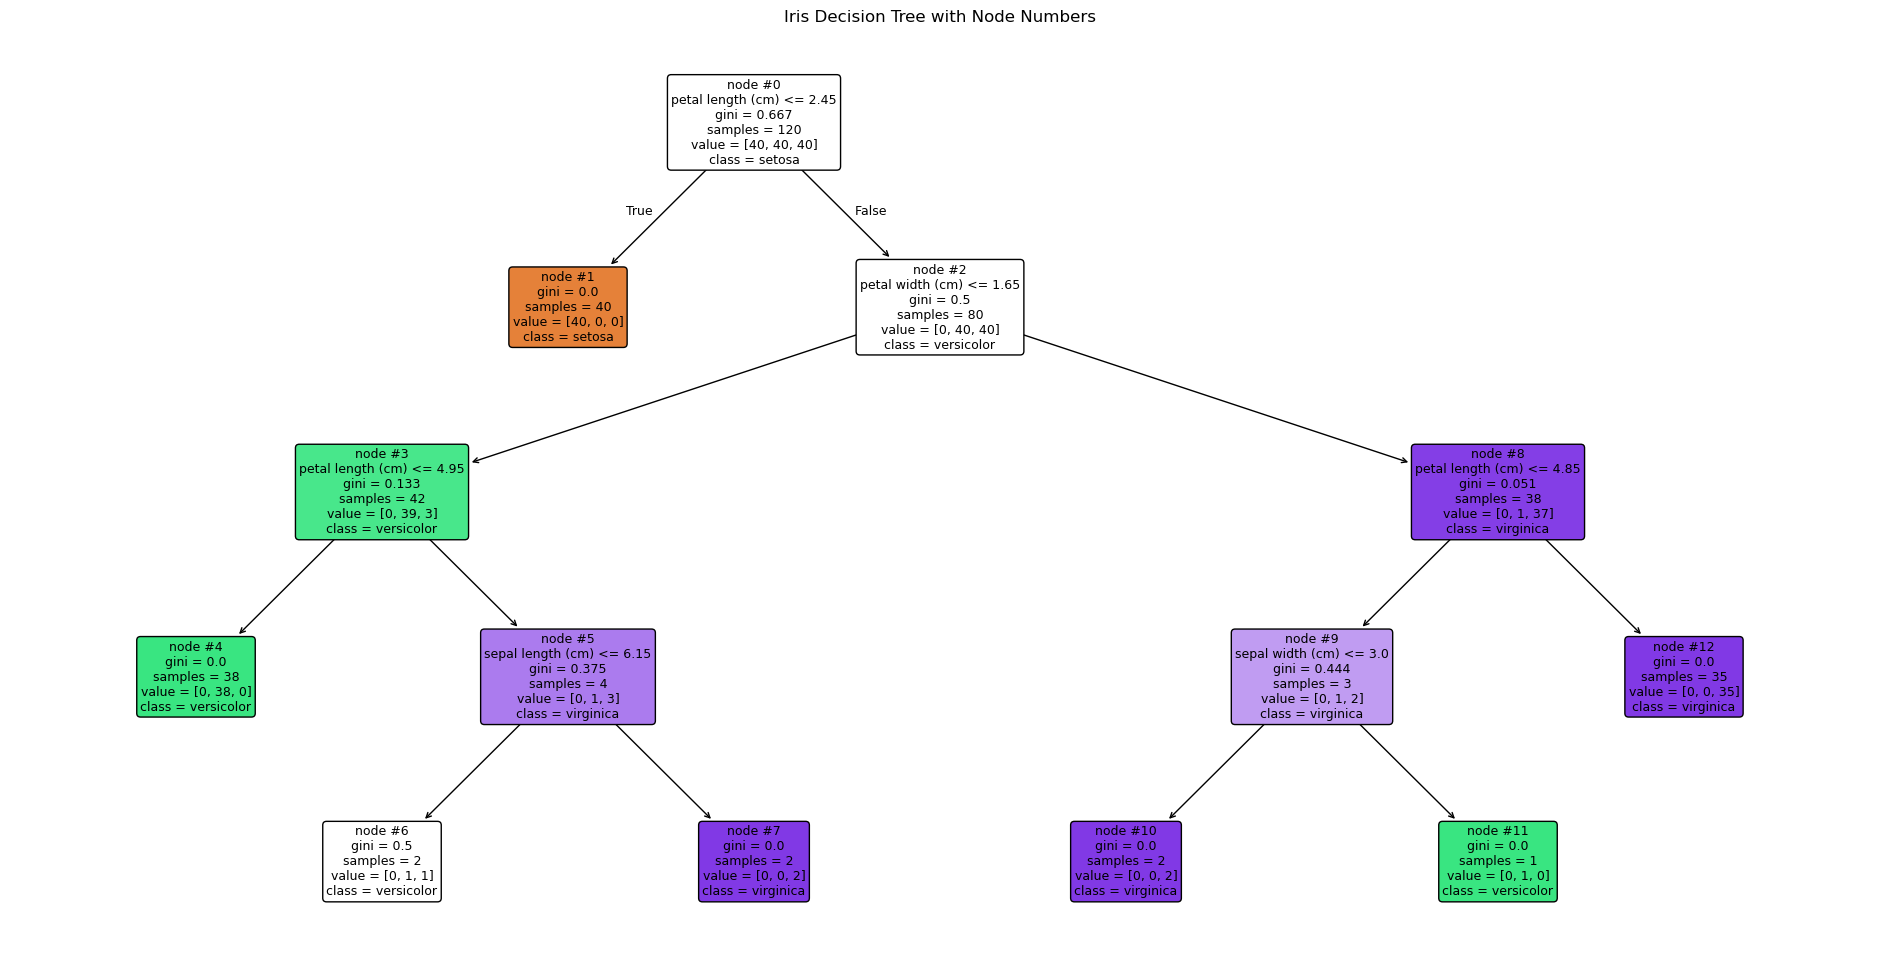

In [16]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train Decision Tree
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)
model.fit(X_train, y_train)

# Draw the tree
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    node_ids=True,
    proportion=False,
    fontsize=9
)

plt.title("Iris Decision Tree with Node Numbers")
plt.show()

In [17]:
%pip install networkx

Note: you may need to restart the kernel to use updated packages.


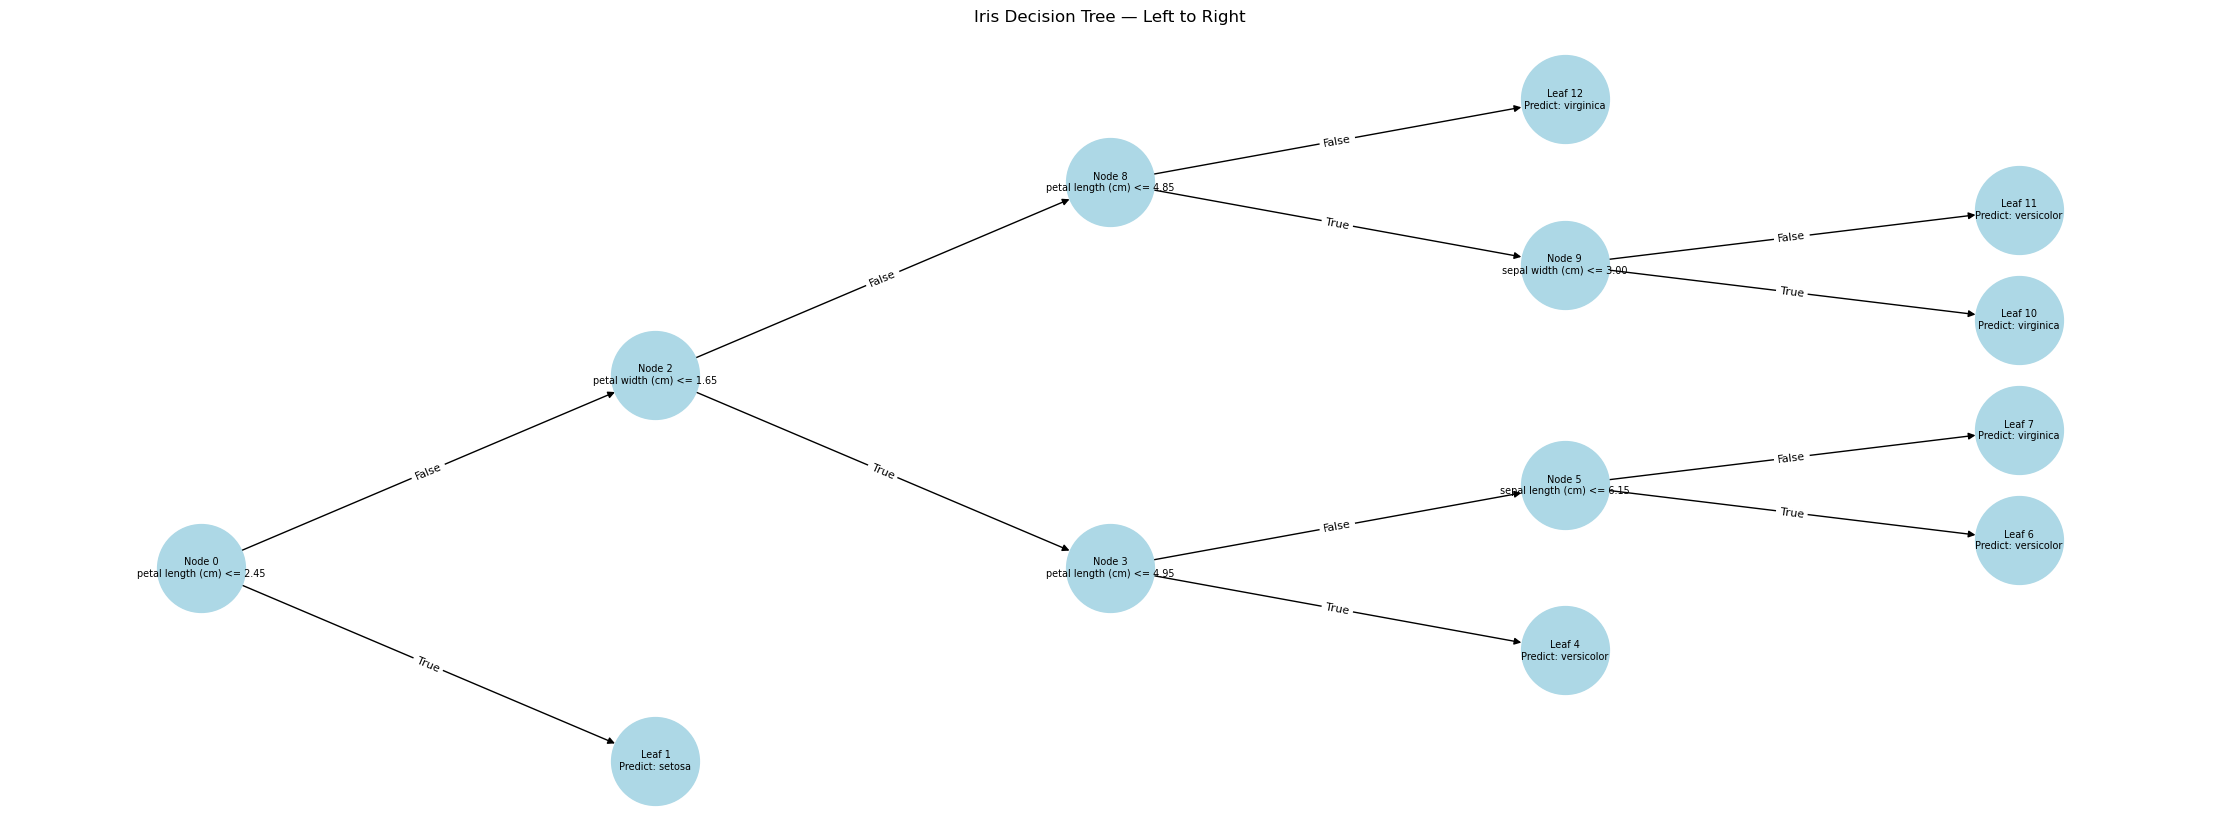

In [18]:
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.tree import _tree

tree = model.tree_
graph = nx.DiGraph()
labels = {}

def add_nodes(node_id=0):
    if tree.feature[node_id] != _tree.TREE_UNDEFINED:
        feature = iris.feature_names[tree.feature[node_id]]
        threshold = tree.threshold[node_id]
        labels[node_id] = f"Node {node_id}\n{feature} <= {threshold:.2f}"
    else:
        prediction = iris.target_names[tree.value[node_id][0].argmax()]
        labels[node_id] = f"Leaf {node_id}\nPredict: {prediction}"

    graph.add_node(node_id)

    left = tree.children_left[node_id]
    right = tree.children_right[node_id]

    if left != _tree.TREE_LEAF:
        graph.add_edge(node_id, left, label="True")
        add_nodes(left)

    if right != _tree.TREE_LEAF:
        graph.add_edge(node_id, right, label="False")
        add_nodes(right)

add_nodes()

# Hierarchical positions: root at left, leaves toward right
def set_positions(node, depth=0, y_pos=None, positions=None):
    if positions is None:
        positions = {}
    if y_pos is None:
        y_pos = [0]

    left = tree.children_left[node]
    right = tree.children_right[node]

    if left != _tree.TREE_LEAF:
        set_positions(left, depth + 1, y_pos, positions)

    if right != _tree.TREE_LEAF:
        set_positions(right, depth + 1, y_pos, positions)

    if left == _tree.TREE_LEAF and right == _tree.TREE_LEAF:
        positions[node] = (depth, y_pos[0])
        y_pos[0] += 1
    else:
        child_positions = [
            positions[child]
            for child in (left, right)
            if child != _tree.TREE_LEAF
        ]
        positions[node] = (
            depth,
            sum(p[1] for p in child_positions) / len(child_positions)
        )

    return positions

pos = set_positions(0)

plt.figure(figsize=(22, max(8, len(labels) * 0.35)))

nx.draw(
    graph,
    pos,
    labels=labels,
    with_labels=True,
    node_size=4000,
    node_color="lightblue",
    font_size=7,
    arrows=True
)

edge_labels = nx.get_edge_attributes(graph, "label")
nx.draw_networkx_edge_labels(
    graph, pos, edge_labels=edge_labels, font_size=8
)

plt.title("Iris Decision Tree — Left to Right")
plt.axis("off")
plt.show()

In [19]:
import numpy as np

sample = X_test[0].reshape(1, -1)

node_ids = model.decision_path(sample).indices
prediction = model.predict(sample)[0]

print("Node path:", node_ids)
print("Predicted species:", iris.target_names[prediction])

for node_id in node_ids:
    if tree.feature[node_id] != _tree.TREE_UNDEFINED:
        feature = iris.feature_names[tree.feature[node_id]]
        threshold = tree.threshold[node_id]
        value = sample[0, tree.feature[node_id]]

        direction = "LEFT" if value <= threshold else "RIGHT"

        print(
            f"Node {node_id}: {feature} = {value:.2f}, "
            f"threshold = {threshold:.2f} -> {direction}"
        )
    else:
        print(f"Node {node_id}: Final leaf")

Node path: [0 1]
Predicted species: setosa
Node 0: petal length (cm) = 1.30, threshold = 2.45 -> LEFT
Node 1: Final leaf
